# INS3155 - Computer Vision Midterm Project
**Traditional Image Processing: Filtering (A), 3D Reconstruction (B), Image Stitching (C)**

- Only classical methods are used (OpenCV, NumPy, SciPy, scikit-image, Matplotlib). No deep learning.
- Run the cells from top to bottom. Only the paths in the **CONFIG** cell need to be edited.
- Outputs are limited to the required deliverables and are saved in `outputs/` (the last cell zips them).

| Part | Visual results | Quantitative table |
|---|---|---|
| A | grid per noise type (original, noisy, denoised, sharpened) and zoomed kernel comparisons | one table: PSNR, SSIM, MSE, time for every filter and setting, both noise types |
| B | epipolar lines, colorized BM vs SGBM disparity, point cloud views | valid ratio, Sampson error, RMSE / bad-pixel, runtime |
| C | keypoints, inlier matches, panorama per detector | keypoints, matches, inliers, inlier ratio, RMSE, time |

In [ ]:
# OPENCV CHECK (run this cell first)
# AKAZE is available in OpenCV 4.x but not in OpenCV 5.0.0 (opencv-python). If AKAZE is missing, install a 4.x build.
# Run this cell BEFORE anything imports cv2. If cv2 was already imported in this session, restart the runtime
# (Runtime -> Restart session) after the install and run all cells again.
import subprocess, sys

def _has_akaze():
    code = "import cv2, sys; sys.exit(0 if (hasattr(cv2, 'AKAZE_create') or hasattr(cv2, 'AKAZE')) else 1)"
    return subprocess.run([sys.executable, "-c", code]).returncode == 0

if _has_akaze():
    print("AKAZE is available in the installed OpenCV.")
else:
    print("AKAZE not found -> installing OpenCV 4.10 ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall", "--no-deps",
                           "opencv-python==4.10.0.84"])
    if "cv2" in sys.modules:
        raise RuntimeError("OpenCV was installed, but cv2 was already imported. "
                           "Restart the runtime (Runtime -> Restart session) and run all cells again.")
    print("Installed. AKAZE available:", _has_akaze())

AKAZE is available in the installed OpenCV.


In [ ]:
# SETUP
import os, re, time, math, warnings, shutil
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as _ssim

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 200)

print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__)
assert hasattr(cv2, "SIFT_create"), "OpenCV >= 4.4 is required for SIFT (Colab has it by default)."

OUT = "outputs"
for sub in ["partA", "partB", "partC", "tables"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

OpenCV: 4.10.0 | NumPy: 2.1.3


In [ ]:
# CONFIG (EDIT HERE)
# To get images into Colab: click the folder icon on the left -> Upload,
# or mount Google Drive and point the paths to Drive.

# Part A: one clean image
PATH_A = "parta.jpg"
A_MAX_SIDE = 512          # resize the longest side for speed (None = keep original size)

# Part B: one stereo pair (Middlebury)
PATH_B_LEFT  = "stereo_L.png"
PATH_B_RIGHT = "stereo_R.png"
PATH_B_GT    = None       # ground-truth disparity image of the left view (None if unavailable)
GT_SCALE     = 4.0        # Middlebury 2003 (Teddy/Cones): disp2.png = disparity * 4
B_MAX_SIDE   = 800        # downscale the pair if too large (GT is scaled accordingly). None = keep original size
FOCAL_PX     = None       # focal length in pixels. None -> use image width (point cloud is correct up to scale only)
BASELINE     = 1.0        # baseline (same unit as the point cloud). Use the real value if calibration is available
RECTIFY_UNCALIBRATED = False  # True if the pair is not rectified (Middlebury pairs are usually already rectified)

# Part C: four panorama images, ordered left to right
PATHS_C = ["partc1.jpg", "partc2.jpg", "partc3.jpg", "partc4.jpg"]
MAX_W_C = 1000            # resize the width of each image for speed
REF_IDX = 1               # reference image index (0..3) that defines the common coordinate frame

SEED = 42

In [ ]:
# (Optional) Upload images directly in Colab
try:
    from google.colab import files
    # files.upload()   # uncomment this line to pick images from your computer
except ImportError:
    pass

In [ ]:
# HELPERS
def read_img(path, flags=cv2.IMREAD_COLOR):
    im = cv2.imread(path, flags)
    if im is None:
        raise FileNotFoundError(f"Cannot read '{path}'. Please upload the image and fix CONFIG.")
    return im

def resize_max_side(img, max_side):
    if not max_side:
        return img, 1.0
    s = min(1.0, max_side / max(img.shape[:2]))
    if s < 1.0:
        img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    return img, s

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img

def savefig(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")

def timeit(fn, repeat=5):
    """Run fn several times and return (result, median time in ms)."""
    ts, out = [], None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn()
        ts.append((time.perf_counter() - t0) * 1000)
    return out, float(np.median(ts))

def show_grid(images, titles, ncols, path=None, suptitle=None, cell=3.2):
    n = len(images)
    nrows = int(math.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell * ncols, cell * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(rgb(im) if im.ndim == 3 else im, cmap="gray", vmin=0, vmax=255)
        ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout()
    if path:
        savefig(fig, path)
    plt.show()

# PART A - Image Filtering and Enhancement (20 pts)
Noise: Gaussian and Salt-and-Pepper. Filters: Mean, Gaussian (several sigmas), Median, Laplacian sharpening; kernels 3/5/7.

$\text{MSE}=\frac1{MN}\sum (I-\hat I)^2,\quad \text{PSNR}=10\log_{10}\frac{255^2}{\text{MSE}},\quad
I_{sharp}=I-c\,\nabla^2 I$

In [ ]:
# A1. Load the image and add noise
img_a_color, _ = resize_max_side(read_img(PATH_A), A_MAX_SIDE)
clean = cv2.cvtColor(img_a_color, cv2.COLOR_BGR2GRAY)
rng = np.random.default_rng(SEED)

def add_gaussian_noise(img, sigma=25):
    return np.clip(img.astype(np.float64) + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

def add_salt_pepper(img, amount=0.05):
    out = img.copy()
    r = rng.random(img.shape)
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out

GAUSS_SIGMA, SP_AMOUNT = 25, 0.05
NOISE_G = f"Gaussian noise (sigma={GAUSS_SIGMA})"
NOISE_SP = f"Salt&Pepper noise (p={SP_AMOUNT})"
noisy = {NOISE_G: add_gaussian_noise(clean, GAUSS_SIGMA), NOISE_SP: add_salt_pepper(clean, SP_AMOUNT)}

In [ ]:
# A2. Filters and metrics
KS = [3, 5, 7]
SIGMAS = [1.0, 2.0]
LAP_C = [0.5]

def f_mean(im, k):
    return cv2.blur(im, (k, k))

def f_gauss(im, k, s):
    return cv2.GaussianBlur(im, (k, k), s)

def f_median(im, k):
    return cv2.medianBlur(im, k)

def _lap_scale(k):
    """Normalize the Laplacian of size k so that the sum of |coefficients| equals that of the standard 3x3 kernel (=8),
    so that sharpening strength is comparable across kernel sizes."""
    imp = np.zeros((41, 41), np.float32)
    imp[20, 20] = 1
    kern = cv2.Laplacian(imp, cv2.CV_32F, ksize=k)
    return 8.0 / float(np.abs(kern).sum())

def f_lap_sharpen(im, k, c):
    lap = cv2.Laplacian(im.astype(np.float32), cv2.CV_32F, ksize=k, scale=_lap_scale(k))
    return np.clip(im.astype(np.float32) - c * lap, 0, 255).astype(np.uint8)

def metrics(ref, out):
    mse = float(np.mean((ref.astype(np.float64) - out.astype(np.float64)) ** 2))
    psnr = float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)
    ssim = float(_ssim(ref, out, data_range=255))
    return mse, psnr, ssim

DENOISE_CFGS, SHARPEN_CFGS = [], []
for k in KS:
    DENOISE_CFGS.append(("Mean", f"k={k}", lambda im, k=k: f_mean(im, k)))
for k in KS:
    for s in SIGMAS:
        DENOISE_CFGS.append(("Gaussian", f"k={k},sigma={s}", lambda im, k=k, s=s: f_gauss(im, k, s)))
for k in KS:
    DENOISE_CFGS.append(("Median", f"k={k}", lambda im, k=k: f_median(im, k)))
for k in KS:
    for c in LAP_C:
        SHARPEN_CFGS.append(("Laplacian sharpen", f"k={k},c={c}", lambda im, k=k, c=c: f_lap_sharpen(im, k, c)))

rowsA, outsA = [], {}
def _record(noise, method, params, out, ms):
    mse, psnr, ssim = metrics(clean, out)
    rowsA.append(dict(Noise=noise, Method=method, Params=params, PSNR_dB=psnr, SSIM=ssim, MSE=mse, Time_ms=ms))
    outsA[(noise, method, params)] = out

for nz, im in noisy.items():
    _record(nz, "No filter", "-", im, 0.0)
    for m, p, fn in DENOISE_CFGS + SHARPEN_CFGS:
        out, ms = timeit(lambda fn=fn, im=im: fn(im))
        _record(nz, m, p, out, ms)

# fixed reference settings, identical for both noise types (used by the visual grids and the Denoise->Sharpen pipeline)
GRID_K, GRID_SIGMA = 5, 1.0
GRID_CFG = {"Mean": f"k={GRID_K}", "Gaussian": f"k={GRID_K},sigma={GRID_SIGMA}", "Median": f"k={GRID_K}"}
PIPE_K, PIPE_C = 3, LAP_C[0]
GRID_DENOISE = {"Mean": lambda im: f_mean(im, GRID_K),
                "Gaussian": lambda im: f_gauss(im, GRID_K, GRID_SIGMA),
                "Median": lambda im: f_median(im, GRID_K)}
for nz in noisy:
    for m, fn in GRID_DENOISE.items():
        out, ms = timeit(lambda fn=fn, nz=nz: f_lap_sharpen(fn(noisy[nz]), PIPE_K, PIPE_C))
        _record(nz, "Denoise->Sharpen", f"{m} {GRID_CFG[m]} + Lap k={PIPE_K},c={PIPE_C}", out, ms)

dfA = pd.DataFrame(rowsA).round({"PSNR_dB": 2, "SSIM": 4, "MSE": 2, "Time_ms": 3})
dfA.to_csv(f"{OUT}/tables/partA_results.csv", index=False)

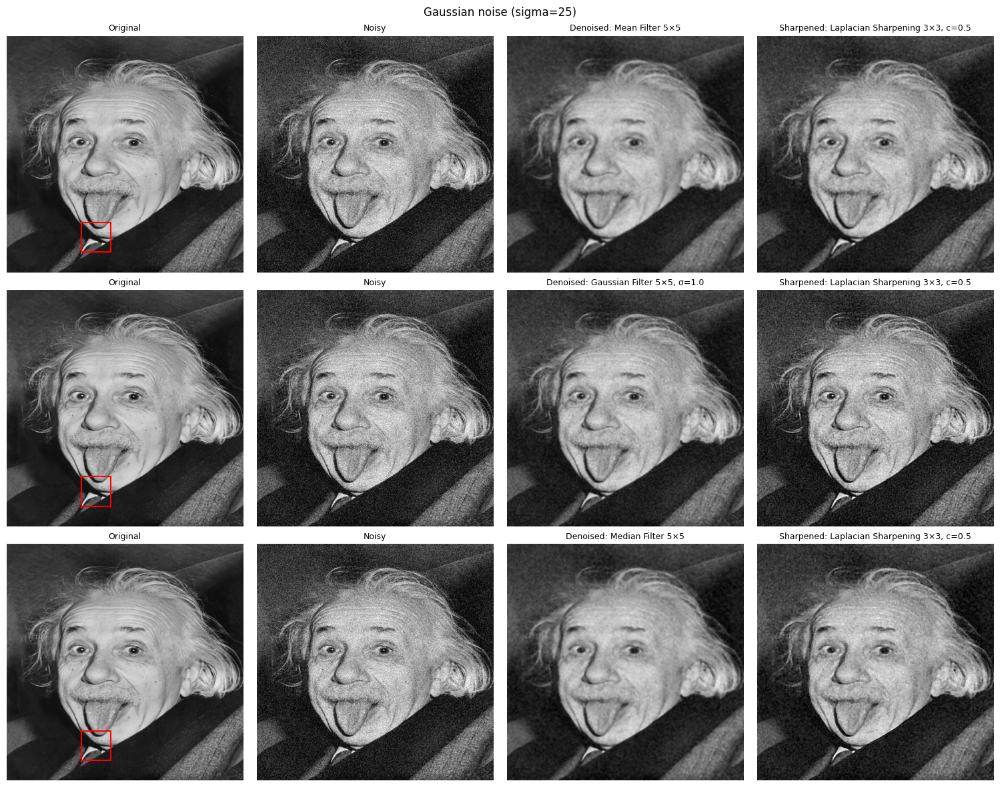

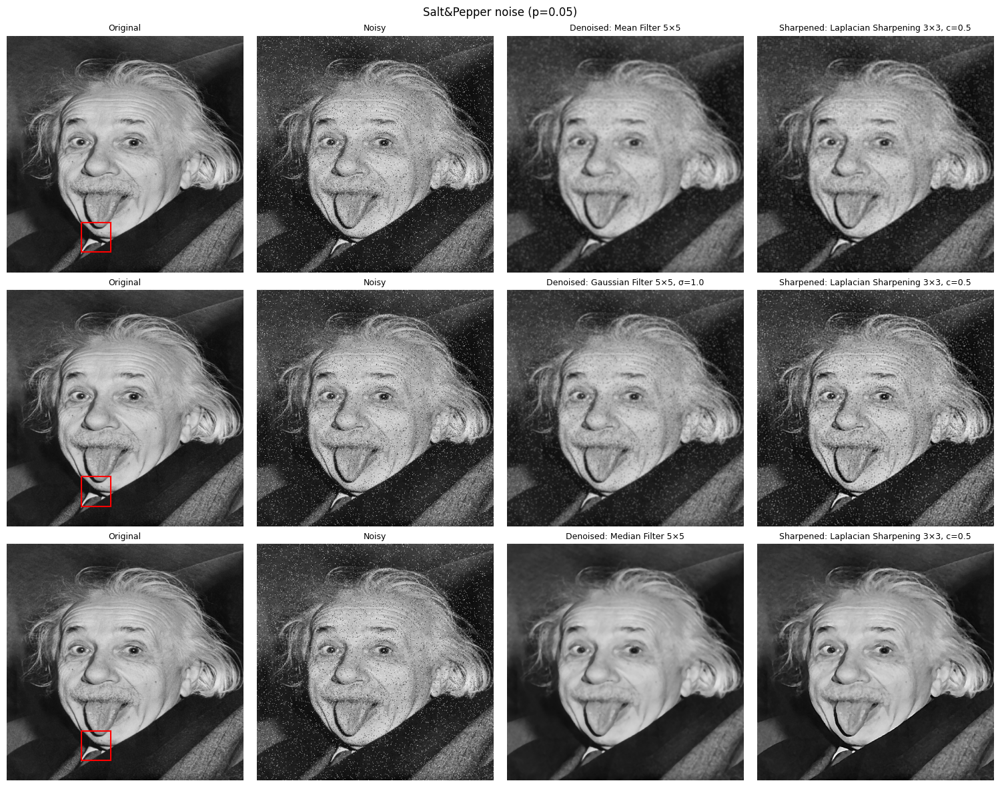

In [ ]:
# A3. VISUAL RESULTS: side-by-side grids (Original | Noisy | Denoised | Sharpened), one grid per noise type
import matplotlib.patches as mpatches

def nice_label(method, params):
    """Readable label from a method name and its parameter string, e.g. 'Gaussian Filter 5x5, sigma=1.0'."""
    k = re.search(r"k=(\d+)", params); k = int(k.group(1)) if k else None
    sg = re.search(r"sigma=([\d.]+)", params); c = re.search(r"c=([\d.]+)", params)
    if method == "Mean":
        return f"Mean Filter {k}\u00d7{k}"
    if method == "Gaussian":
        return f"Gaussian Filter {k}\u00d7{k}, \u03c3={sg.group(1)}"
    if method == "Median":
        return f"Median Filter {k}\u00d7{k}"
    if method == "Laplacian sharpen":
        return f"Laplacian Sharpening {k}\u00d7{k}, c={c.group(1)}"
    return method

def get_result(nz, method, params):
    return outsA[(nz, method, params)]

# strongest-edge 64x64 region: marked on the Original tile and zoomed in A4
CROP = 64
_gx = cv2.Sobel(clean.astype(np.float32), cv2.CV_32F, 1, 0); _gy = cv2.Sobel(clean.astype(np.float32), cv2.CV_32F, 0, 1)
_e = cv2.boxFilter(_gx ** 2 + _gy ** 2, -1, (CROP, CROP), normalize=True)
_cy, _cx = np.unravel_index(np.argmax(_e), _e.shape)
y0 = int(np.clip(_cy - CROP // 2, 0, clean.shape[0] - CROP)); x0 = int(np.clip(_cx - CROP // 2, 0, clean.shape[1] - CROP))

for nz in noisy:
    tag = "gaussian_noise" if nz == NOISE_G else "salt_pepper_noise"
    fig, axes = plt.subplots(len(GRID_DENOISE), 4, figsize=(15, 3.9 * len(GRID_DENOISE)), constrained_layout=True)
    for ri, m in enumerate(GRID_DENOISE):
        den = get_result(nz, m, GRID_CFG[m])
        shp = get_result(nz, "Denoise->Sharpen", f"{m} {GRID_CFG[m]} + Lap k={PIPE_K},c={PIPE_C}")
        tiles = [(clean, "Original"), (noisy[nz], "Noisy"),
                 (den, "Denoised: " + nice_label(m, GRID_CFG[m])),
                 (shp, f"Sharpened: Laplacian Sharpening {PIPE_K}\u00d7{PIPE_K}, c={PIPE_C}")]
        for ci, (im, t) in enumerate(tiles):
            axes[ri, ci].imshow(im, cmap="gray", vmin=0, vmax=255); axes[ri, ci].set_title(t, fontsize=9); axes[ri, ci].axis("off")
        axes[ri, 0].add_patch(mpatches.Rectangle((x0, y0), CROP, CROP, fill=False, edgecolor="red", lw=1.5))
    fig.suptitle(nz, fontsize=12)
    savefig(fig, f"{OUT}/partA/partA_grid_{tag}.png"); plt.show()

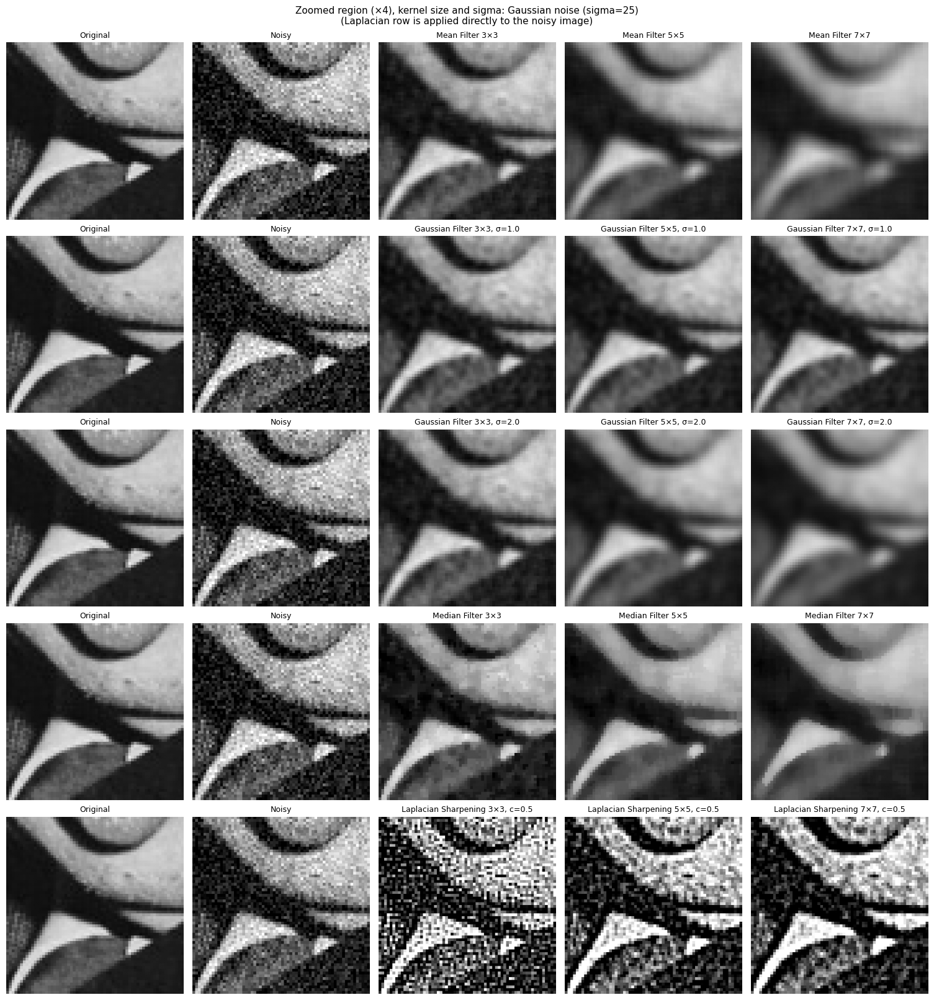

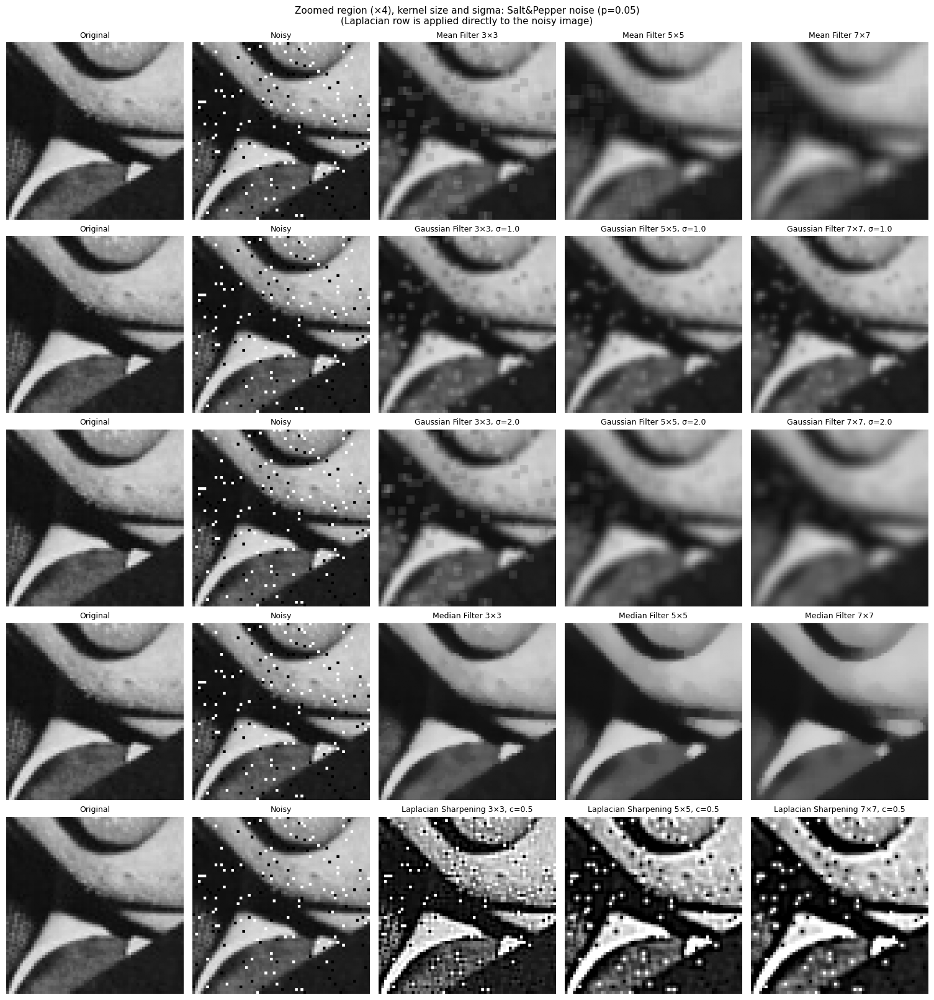

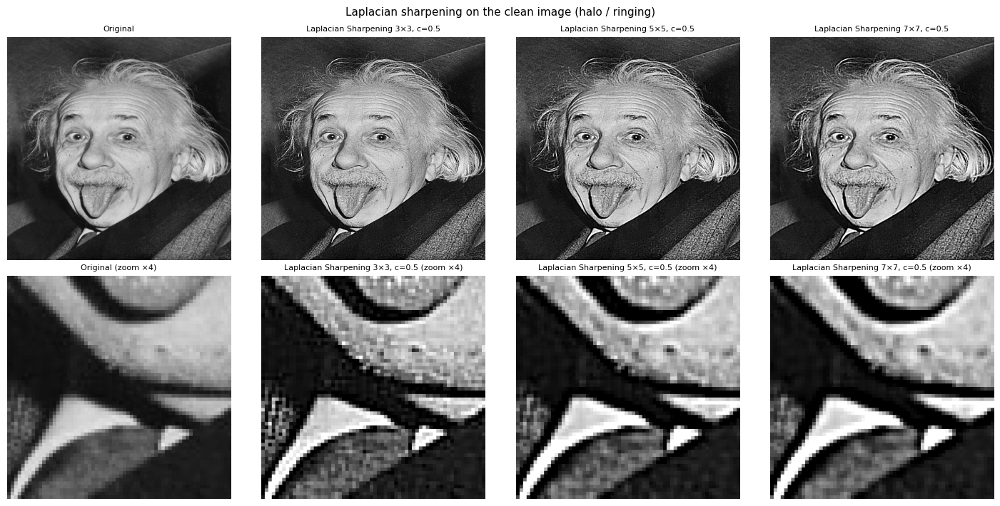

In [ ]:
# A4. QUALITATIVE EVIDENCE: zoomed edge region (x4) to compare kernel sizes and sigma (red box in A3 marks the region)
def crop_zoom(im, scale=4):
    return cv2.resize(im[y0:y0 + CROP, x0:x0 + CROP], None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)

KERNEL_ROWS = ([("Mean", lambda k: f"k={k}")]
               + [("Gaussian", (lambda k, s=s: f"k={k},sigma={s}")) for s in SIGMAS]
               + [("Median", lambda k: f"k={k}")]
               + [("Laplacian sharpen", (lambda k, c=c: f"k={k},c={c}")) for c in LAP_C])

for nz in noisy:
    tag = "gaussian_noise" if nz == NOISE_G else "salt_pepper_noise"
    fig, axes = plt.subplots(len(KERNEL_ROWS), 2 + len(KS), figsize=(3.0 * (2 + len(KS)), 3.2 * len(KERNEL_ROWS)), constrained_layout=True)
    for ri, (method, pfun) in enumerate(KERNEL_ROWS):
        tiles = [(clean, "Original"), (noisy[nz], "Noisy")] + [(get_result(nz, method, pfun(k)), nice_label(method, pfun(k))) for k in KS]
        for ci, (im, t) in enumerate(tiles):
            axes[ri, ci].imshow(crop_zoom(im), cmap="gray", vmin=0, vmax=255); axes[ri, ci].set_title(t, fontsize=9); axes[ri, ci].axis("off")
    fig.suptitle(f"Zoomed region (\u00d74), kernel size and sigma: {nz}\n(Laplacian row is applied directly to the noisy image)", fontsize=11)
    savefig(fig, f"{OUT}/partA/partA_kernel_comparison_{tag}.png"); plt.show()

# Laplacian sharpening on the CLEAN image (full view and zoom): halo / ringing without any noise
sharp_set = [("Original", clean)] + [(nice_label("Laplacian sharpen", f"k={k},c={c}"), f_lap_sharpen(clean, k, c)) for k in KS for c in LAP_C]
show_grid([t[1] for t in sharp_set] + [crop_zoom(t[1]) for t in sharp_set],
          [t[0] for t in sharp_set] + [t[0] + " (zoom \u00d74)" for t in sharp_set], len(sharp_set),
          f"{OUT}/partA/partA_laplacian_sharpening_clean_image.png", suptitle="Laplacian sharpening on the clean image (halo / ringing)", cell=3.6)

Table: filters and parameter settings on both noise types (Laplacian rows are applied directly to the noisy image)


Gaussian noise (sigma=25)                          Salt&Pepper noise (p=0.05)                         
                                                  PSNR_dB    SSIM      MSE Time_ms                    PSNR_dB    SSIM      MSE Time_ms
Noisy (no filter)                                   20.49  0.3244   581.23   0.000                      17.84  0.3737  1068.73   0.000
Mean Filter 3×3                                     27.67  0.6522   111.26   0.146                      25.63  0.5780   178.06   0.132
Mean Filter 5×5                                     27.04  0.6694   128.60   0.165                      26.04  0.6103   161.71   0.153
Mean Filter 7×7                                     26.06  0.6441   160.94   0.422                      25.45  0.6079   185.48   0.425
Gaussian Filter 3×3, σ=1.0                          27.81  0.6565   107.59   0.177                      25.55  0.5856   181.31   0.169
Gaussian Filter 3×3, σ=2.0                          27.76  0.6572   108.91   0.179                      25.68  0.5831   176.02   0.167
Gaussian Filter 5×5, σ=1.0                          28.25  0.6964    97.34   0.292                      26.33  0.6228   151.24   0.248
Gaussian Filter 5×5, σ=2.0                          27.59  0.6978   113.33   0.256                      26.42  0.6360   148.23   0.268
Gaussian Filter 7×7, σ=1.0                          28.26  0.6994    97.02   0.589                      26.39  0.6260   149.28   0.542
Gaussian Filter 7×7, σ=2.0                          27.12  0.6984   126.11   0.712                      26.26  0.6530   153.77   0.576
Median Filter 3×3                                   26.38  0.5693   149.79   0.475                      32.12  0.8963    39.90   0.497
Median Filter 5×5                                   26.80  0.6230   135.87   3.206                      28.63  0.7766    89.10   3.249
Median Filter 7×7                                   26.23  0.6251   155.08  11.385                      27.03  0.7046   128.83  11.209
Laplacian Sharpening 3×3, c=0.5                     11.99  0.1188  4109.85   0.997                      15.70  0.2935  1749.84   1.953
Laplacian Sharpening 5×5, c=0.5                     14.88  0.1990  2114.99   2.387                      15.47  0.2887  1843.64   6.557
Laplacian Sharpening 7×7, c=0.5                     16.05  0.2349  1613.57   2.066                      15.73  0.2999  1737.52   7.044


Table: denoise followed by Laplacian sharpening (the Denoised / Sharpened columns of the grids in A3)


Gaussian noise (sigma=25)                         Salt&Pepper noise (p=0.05)                        
                                                                     PSNR_dB    SSIM     MSE Time_ms                    PSNR_dB    SSIM     MSE Time_ms
Mean Filter 5×5 + Laplacian Sharpening 3×3, c=0.5                      25.22  0.4953  195.25   1.479                      23.68  0.4220  278.85   3.947
Gaussian Filter 5×5, σ=1.0 + Laplacian Sharpeni...                     25.21  0.5361  196.12   5.139                      22.70  0.4919  348.85   3.874
Median Filter 5×5 + Laplacian Sharpening 3×3, c...                     23.48  0.3966  291.81   9.178                      27.13  0.7439  125.93  10.940

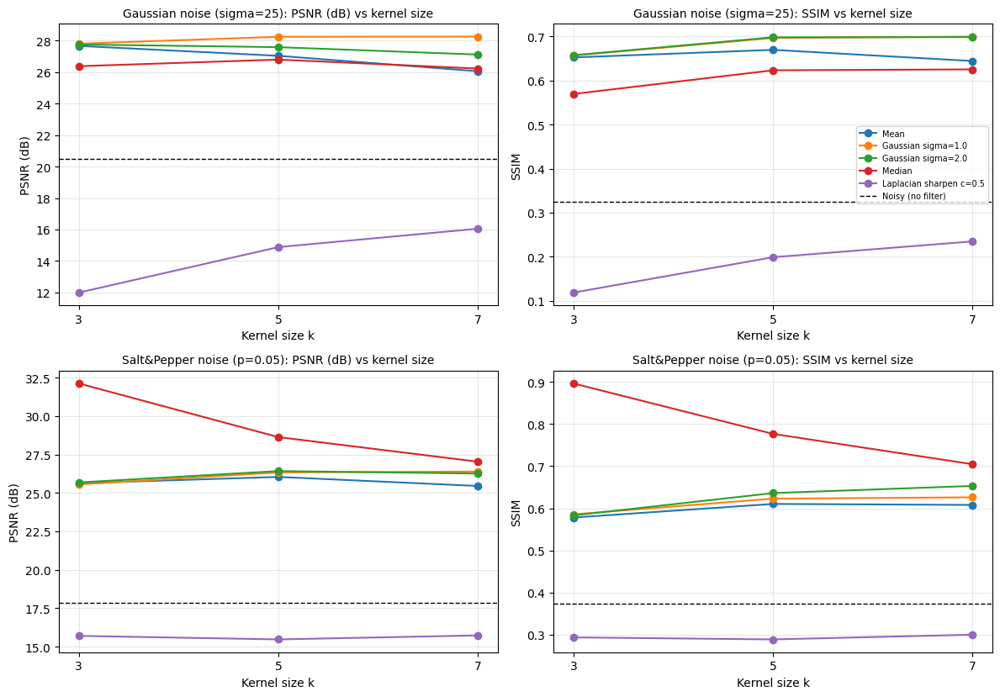

In [ ]:
# A5. QUANTITATIVE EVALUATION: one comparative table (both noise types side by side) and one chart
def label_of(method, params):
    if method == "No filter":
        return "Noisy (no filter)"
    if method == "Denoise->Sharpen":
        den_part, lap_part = params.split(" + ")
        m = den_part.split(" ")[0]
        return nice_label(m, den_part[len(m) + 1:]) + " + " + nice_label("Laplacian sharpen", lap_part.replace("Lap ", ""))
    return nice_label(method, params)

def wide_table(rows):
    idx = dfA.set_index(["Noise", "Method", "Params"])
    parts = []
    for nz in noisy:
        parts.append(pd.DataFrame([idx.loc[(nz, m, p), ["PSNR_dB", "SSIM", "MSE", "Time_ms"]].values for m, p in rows],
                                  index=[label_of(m, p) for m, p in rows], columns=["PSNR_dB", "SSIM", "MSE", "Time_ms"]))
    return pd.concat(parts, axis=1, keys=list(noisy))

rows_main = [("No filter", "-")] + [(m, p) for m, p, _ in DENOISE_CFGS + SHARPEN_CFGS]
tab_main = wide_table(rows_main)
print("Table: filters and parameter settings on both noise types (Laplacian rows are applied directly to the noisy image)")
display(tab_main); tab_main.to_csv(f"{OUT}/tables/partA_comparison_table.csv")

rows_pipe = [("Denoise->Sharpen", f"{m} {GRID_CFG[m]} + Lap k={PIPE_K},c={PIPE_C}") for m in GRID_DENOISE]
tab_pipe = wide_table(rows_pipe)
print("\nTable: denoise followed by Laplacian sharpening (the Denoised / Sharpened columns of the grids in A3)")
display(tab_pipe); tab_pipe.to_csv(f"{OUT}/tables/partA_denoise_then_sharpen_table.csv")

dfK = dfA[dfA.Method.isin(["Mean", "Gaussian", "Median", "Laplacian sharpen"])].copy()
dfK["k"] = dfK.Params.str.extract(r"k=(\d+)")[0].astype(int)
dfK["Setting"] = (dfK.Method + " " + dfK.Params.str.replace(r"k=\d+,?", "", regex=True)).str.strip()
fig, axes = plt.subplots(len(noisy), 2, figsize=(12, 4.2 * len(noisy)))
for ri, nz in enumerate(noisy):
    base = dfA[(dfA.Noise == nz) & (dfA.Method == "No filter")].iloc[0]
    for ci, (col, lab) in enumerate([("PSNR_dB", "PSNR (dB)"), ("SSIM", "SSIM")]):
        ax = axes[ri, ci]
        for setting, g in dfK[dfK.Noise == nz].groupby("Setting", sort=False):
            g = g.sort_values("k"); ax.plot(g.k, g[col], marker="o", label=setting)
        ax.axhline(base[col], color="k", ls="--", lw=1, label="Noisy (no filter)")
        ax.set_xticks(KS); ax.set_xlabel("Kernel size k"); ax.set_ylabel(lab); ax.grid(alpha=.3)
        ax.set_title(f"{nz}: {lab} vs kernel size", fontsize=10)
        if ri == 0 and ci == 1:
            ax.legend(fontsize=7, loc="best")
fig.tight_layout(); savefig(fig, f"{OUT}/partA/partA_metrics_vs_kernel_size.png"); plt.show()

In [ ]:
# A6. Save the full-frame result of EVERY setting (all filters, kernel sizes and sigmas, both noise types) as individual PNG files
# for the "generated visual outputs" of the submission ZIP. Nothing is displayed here.
ALL_DIR = f"{OUT}/partA/all_results"
os.makedirs(ALL_DIR, exist_ok=True)
cv2.imwrite(f"{ALL_DIR}/original.png", clean)
n_saved = 0
for (nz, method, params), im in outsA.items():
    folder = f"{ALL_DIR}/{'gaussian_noise' if nz == NOISE_G else 'salt_pepper_noise'}"
    os.makedirs(folder, exist_ok=True)
    name = re.sub(r"[^A-Za-z0-9.]+", "_", f"{method}_{params}").strip("_").lower()
    cv2.imwrite(f"{folder}/{name}.png", im); n_saved += 1
print(f"Saved {n_saved} result images in {ALL_DIR}/ (one folder per noise type)")

Saved 38 result images in outputs/partA/all_results/ (one folder per noise type)


**Where to find the evidence for the Part A qualitative discussion**
- Noise removal vs edge preservation: the zoomed comparison `partA_kernel_comparison_*` (A4) together with PSNR / SSIM in the table (A5).
- Over-smoothing: compare the 3x3, 5x5 and 7x7 columns (and sigma = 1.0 vs 2.0) in the same zoomed figure; Mean 7x7 and Median 7x7 lose the most detail.
- Halo / ringing: `partA_laplacian_sharpening_clean_image` (A4) shows bright / dark rims along edges even without noise.
- Noise amplification: the Laplacian row applied directly to the noisy image, and the Sharpened column in the grids of A3.
- Full-frame result of every kernel size / sigma: saved as separate PNG files in `outputs/partA/all_results/` (A6).

# PART B - 3D Reconstruction from Stereo (25 pts)
1. SIFT + ratio test -> Fundamental matrix **F** via RANSAC -> draw epipolar lines.
2. Disparity: **BM** vs **SGBM**, varying `blockSize` and `numDisparities`.
3. Point cloud: $Z=\dfrac{fB}{d},\ X=\dfrac{(x-c_x)Z}{f},\ Y=\dfrac{(y-c_y)Z}{f}$.

Sampson error: $\;\dfrac{(x_2^\top F x_1)^2}{(Fx_1)_1^2+(Fx_1)_2^2+(F^\top x_2)_1^2+(F^\top x_2)_2^2}$

In [ ]:
# B1. Load and resize the stereo pair
L_color = read_img(PATH_B_LEFT); R_color = read_img(PATH_B_RIGHT)
assert L_color.shape == R_color.shape, "The two stereo images must have the same size."
L_color, sB = resize_max_side(L_color, B_MAX_SIDE)
R_color = cv2.resize(R_color, (L_color.shape[1], L_color.shape[0]), interpolation=cv2.INTER_AREA) if sB < 1 else R_color
gL = cv2.cvtColor(L_color, cv2.COLOR_BGR2GRAY); gR = cv2.cvtColor(R_color, cv2.COLOR_BGR2GRAY)
hB, wB = gL.shape
print("Stereo size:", (wB, hB))

gt = None
if PATH_B_GT and os.path.exists(PATH_B_GT):
    g = cv2.imread(PATH_B_GT, cv2.IMREAD_UNCHANGED).astype(np.float32)
    g = g[..., 0] if g.ndim == 3 else g
    if g.shape != gL.shape:
        g = cv2.resize(g, (wB, hB), interpolation=cv2.INTER_NEAREST)
    gt = g / GT_SCALE * sB          # disparity (pixels) at the working resolution
    print("Ground truth loaded.")
else:
    print("No ground truth -> RMSE / bad-pixel metrics are skipped.")

Stereo size: (450, 375)
No ground truth -> RMSE / bad-pixel metrics are skipped.


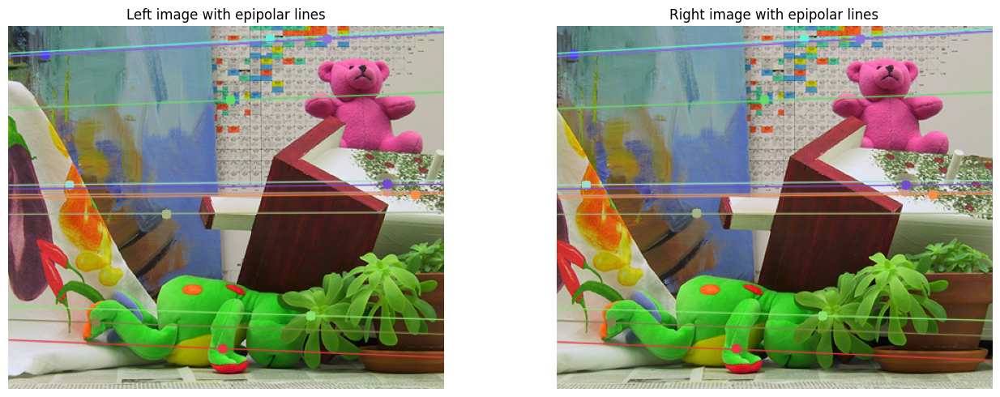

,Stage,Matches,RANSAC_inliers,Inlier_ratio_pct,Mean_epipolar_err_px,Mean_Sampson_err_px,Median_vertical_shift_px
0,original pair,337,315,93.472,0.239,0.169,0.117


In [ ]:
# B2. Fundamental matrix (RANSAC) and epipolar lines
def hom(p):
    return np.hstack([p, np.ones((len(p), 1))])

def sampson_dist(F, p1, p2):
    """Sampson distance (px) for each point pair."""
    x1, x2 = hom(p1), hom(p2)
    Fx1, Ftx2 = x1 @ F.T, x2 @ F
    num = np.sum(x2 * Fx1, axis=1) ** 2
    den = Fx1[:, 0] ** 2 + Fx1[:, 1] ** 2 + Ftx2[:, 0] ** 2 + Ftx2[:, 1] ** 2
    return np.sqrt(num / np.maximum(den, 1e-12))

def epipolar_dist(F, p1, p2):
    """Symmetric point-to-epipolar-line distance (px)."""
    x1, x2 = hom(p1), hom(p2)
    l2, l1 = x1 @ F.T, x2 @ F
    d2 = np.abs(np.sum(x2 * l2, axis=1)) / np.maximum(np.hypot(l2[:, 0], l2[:, 1]), 1e-12)
    d1 = np.abs(np.sum(x1 * l1, axis=1)) / np.maximum(np.hypot(l1[:, 0], l1[:, 1]), 1e-12)
    return 0.5 * (d1 + d2)

def estimate_F(g1, g2, ratio=0.75, thr=1.0, conf=0.99):
    sift = cv2.SIFT_create()
    k1, d1 = sift.detectAndCompute(g1, None); k2, d2 = sift.detectAndCompute(g2, None)
    knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    p1 = np.float32([k1[m.queryIdx].pt for m in good]); p2 = np.float32([k2[m.trainIdx].pt for m in good])
    F, mask = cv2.findFundamentalMat(p1, p2, cv2.FM_RANSAC, thr, conf)
    if F is None or mask is None:
        raise RuntimeError("Could not estimate F (too few matches). Check the image pair.")
    F = F[:3] if F.shape[0] > 3 else F                  # OpenCV may return several solutions
    F = F / np.linalg.norm(F)                           # normalize the scale (F is defined up to a constant)
    inl = mask.ravel() == 1
    return dict(F=F, p1=p1, p2=p2, inl=inl, n_good=len(good))

def draw_epilines(img, lines, pts, seed=0):
    img = img.copy(); h, w = img.shape[:2]; r = np.random.default_rng(seed)
    for (a, b, c), p in zip(lines, pts):
        col = tuple(int(x) for x in r.integers(50, 255, 3))
        if abs(b) > 1e-9:
            cv2.line(img, (0, int(-c / b)), (w, int(-(c + a * w) / b)), col, 1, cv2.LINE_AA)
        cv2.circle(img, (int(p[0]), int(p[1])), 5, col, -1)
    return img

def epipolar_report(est, tag):
    F, inl = est["F"], est["inl"]
    p1, p2 = est["p1"][inl], est["p2"][inl]
    return dict(Stage=tag, Matches=est["n_good"], RANSAC_inliers=int(inl.sum()), Inlier_ratio_pct=100 * inl.mean(),
                Mean_epipolar_err_px=float(epipolar_dist(F, p1, p2).mean()),
                Mean_Sampson_err_px=float(sampson_dist(F, p1, p2).mean()),
                Median_vertical_shift_px=float(np.median(np.abs(p1[:, 1] - p2[:, 1]))))

estF = estimate_F(gL, gR)
repF = [epipolar_report(estF, "original pair")]

rs = np.random.default_rng(0)
inl_idx = np.flatnonzero(estF["inl"])
sel = rs.choice(inl_idx, size=min(12, len(inl_idx)), replace=False)
pL, pR = estF["p1"][sel], estF["p2"][sel]
linesR = cv2.computeCorrespondEpilines(pL.reshape(-1, 1, 2), 1, estF["F"]).reshape(-1, 3)
linesL = cv2.computeCorrespondEpilines(pR.reshape(-1, 1, 2), 2, estF["F"]).reshape(-1, 3)
epiL = draw_epilines(L_color, linesL, pL, seed=1); epiR = draw_epilines(R_color, linesR, pR, seed=1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(rgb(epiL)); ax[0].set_title("Left image with epipolar lines")
ax[1].imshow(rgb(epiR)); ax[1].set_title("Right image with epipolar lines")
for a in ax: a.axis("off")
fig.tight_layout(); savefig(fig, f"{OUT}/partB/B_epipolar_lines.png"); plt.show()

# optional: rectify using F if the pair is not rectified
F_use, gL_use, gR_use, L_use = estF["F"], gL, gR, L_color
if RECTIFY_UNCALIBRATED:
    p1i, p2i = estF["p1"][estF["inl"]], estF["p2"][estF["inl"]]
    ok, H1, H2 = cv2.stereoRectifyUncalibrated(p1i, p2i, estF["F"], (wB, hB))
    if ok:
        gL_use = cv2.warpPerspective(gL, H1, (wB, hB)); gR_use = cv2.warpPerspective(gR, H2, (wB, hB))
        L_use = cv2.warpPerspective(L_color, H1, (wB, hB))
        est_r = estimate_F(gL_use, gR_use); F_use = est_r["F"]
        repF.append(epipolar_report(est_r, "after uncalibrated rectification"))
        if gt is not None:
            print("WARNING: GT no longer matches after rectification -> RMSE/Bad-pixel are not reliable.")
dfF = pd.DataFrame(repF).round(3)
display(dfF); dfF.to_csv(f"{OUT}/tables/partB_fundamental_matrix.csv", index=False)
if repF[0]["Median_vertical_shift_px"] > 2 and not RECTIFY_UNCALIBRATED:
    print("Note: median vertical shift > 2px -> the pair seems not rectified, try RECTIFY_UNCALIBRATED=True.")

In [ ]:
# B3. Disparity: BM vs SGBM with different blockSize and numDisparities
def run_bm(a, b, nd, bs):
    bm = cv2.StereoBM_create(numDisparities=nd, blockSize=bs)
    bm.setPreFilterType(cv2.STEREO_BM_PREFILTER_XSOBEL); bm.setPreFilterCap(31)
    bm.setTextureThreshold(10); bm.setUniquenessRatio(10)
    bm.setSpeckleWindowSize(100); bm.setSpeckleRange(2); bm.setDisp12MaxDiff(1)
    return bm.compute(a, b).astype(np.float32) / 16.0

def run_sgbm(a, b, nd, bs):
    sg = cv2.StereoSGBM_create(minDisparity=0, numDisparities=nd, blockSize=bs,
                               P1=8 * bs * bs, P2=32 * bs * bs, disp12MaxDiff=1, uniquenessRatio=10,
                               speckleWindowSize=100, speckleRange=2, preFilterCap=63,
                               mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY)
    return sg.compute(a, b).astype(np.float32) / 16.0

def colorize(disp, nd):
    d = np.clip(disp / nd, 0, 1)
    c = cv2.applyColorMap((d * 255).astype(np.uint8), cv2.COLORMAP_JET)
    c[disp <= 0] = 0
    return c

ND_LIST = [64, 128]
BM_BS = [5, 15]
SGBM_BS = [3, 7]

rowsB, dispB = [], {}
rs2 = np.random.default_rng(1)
def eval_disp(disp, method, nd, bs, ms):
    valid = disp > 0
    row = dict(Method=method, numDisparities=nd, blockSize=bs, Valid_disparity_pct=100 * valid.mean())
    ys, xs = np.nonzero(valid)
    if len(xs) > 0:
        idx = rs2.choice(len(xs), size=min(5000, len(xs)), replace=False)
        p1 = np.stack([xs[idx], ys[idx]], 1).astype(np.float64)
        p2 = p1.copy(); p2[:, 0] -= disp[ys[idx], xs[idx]]
        row["Mean_Sampson_err_px"] = float(sampson_dist(F_use, p1, p2).mean())
    else:
        row["Mean_Sampson_err_px"] = np.nan
    if gt is not None:
        m = (gt > 0) & valid
        if m.any():
            e = np.abs(disp[m] - gt[m])
            row.update(RMSE_px=float(np.sqrt(np.mean(e ** 2))), Bad2_pct=100 * float((e > 2).mean()))
    row["Runtime_ms"] = ms
    return row

for nd in ND_LIST:
    for bs in BM_BS:
        d, ms = timeit(lambda nd=nd, bs=bs: run_bm(gL_use, gR_use, nd, bs), repeat=3)
        dispB[("BM", nd, bs)] = d; rowsB.append(eval_disp(d, "BM", nd, bs, ms))
    for bs in SGBM_BS:
        d, ms = timeit(lambda nd=nd, bs=bs: run_sgbm(gL_use, gR_use, nd, bs), repeat=3)
        dispB[("SGBM", nd, bs)] = d; rowsB.append(eval_disp(d, "SGBM", nd, bs, ms))

dfB = pd.DataFrame(rowsB).round(3)
dfB.to_csv(f"{OUT}/tables/partB_disparity_results.csv", index=False)
display(dfB)

,Method,numDisparities,blockSize,Valid_disparity_pct,Mean_Sampson_err_px,Runtime_ms
0,BM,64,5,53.964,0.191,21.473
1,BM,64,15,69.903,0.188,13.625
2,SGBM,64,3,81.016,0.187,31.441
3,SGBM,64,7,81.169,0.191,32.177
4,BM,128,5,39.815,0.188,20.518
5,BM,128,15,56.554,0.185,24.533
6,SGBM,128,3,67.026,0.180,42.959
7,SGBM,128,7,67.025,0.184,46.465


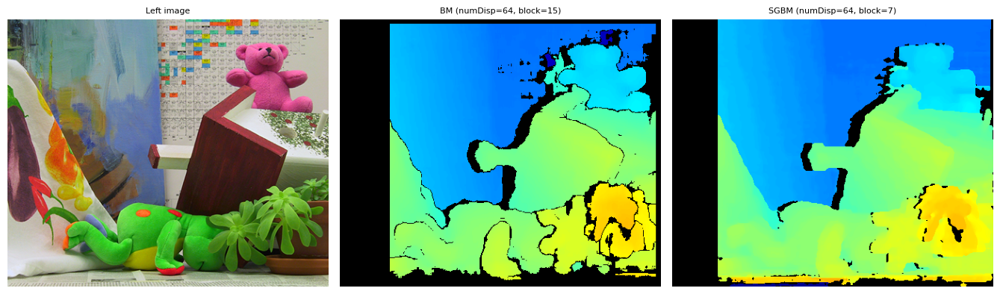

In [ ]:
# B4. Colorized disparity maps: best BM vs best SGBM
def pick_best(method):
    sub = dfB[dfB.Method == method]
    if "Bad2_pct" in sub and sub.Bad2_pct.notna().any():
        return sub.loc[sub.Bad2_pct.idxmin()]
    return sub.loc[sub.Valid_disparity_pct.idxmax()]

bestBM, bestSG = pick_best("BM"), pick_best("SGBM")
kBM = ("BM", int(bestBM.numDisparities), int(bestBM.blockSize))
kSG = ("SGBM", int(bestSG.numDisparities), int(bestSG.blockSize))

imgs = [L_use, colorize(dispB[kBM], kBM[1]), colorize(dispB[kSG], kSG[1])]
titles = ["Left image", f"BM (numDisp={kBM[1]}, block={kBM[2]})", f"SGBM (numDisp={kSG[1]}, block={kSG[2]})"]
if gt is not None:
    imgs.insert(1, colorize(gt, max(kBM[1], kSG[1]))); titles.insert(1, "Ground truth")
show_grid(imgs, titles, len(imgs), f"{OUT}/partB/B_disparity_bm_vs_sgbm.png", cell=4.5)

Point cloud: 134,225 points


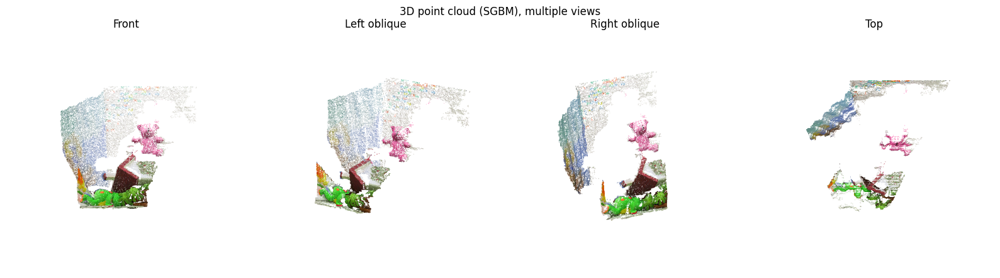

In [ ]:
# B5. 3D point cloud from the best SGBM disparity
disp3d = dispB[kSG].copy()
f_px = FOCAL_PX if FOCAL_PX else float(wB)
cx, cy = wB / 2.0, hB / 2.0
Q = np.float32([[1, 0, 0, -cx], [0, 1, 0, -cy], [0, 0, 0, f_px], [0, 0, 1.0 / BASELINE, 0]])
pts3d = cv2.reprojectImageTo3D(disp3d, Q)            # X=(x-cx)B/d, Y=(y-cy)B/d, Z=fB/d
mask = (disp3d > 0) & np.isfinite(pts3d).all(axis=2)
P = pts3d[mask]; C = L_use[mask][:, ::-1]            # BGR -> RGB
zhi = np.percentile(P[:, 2], 99); keep = P[:, 2] < zhi
P, C = P[keep], C[keep]
print(f"Point cloud: {len(P):,} points")

def save_ply(path, P, C):
    with open(path, "w") as f:
        f.write("ply\nformat ascii 1.0\n" f"element vertex {len(P)}\n"
                "property float x\nproperty float y\nproperty float z\n"
                "property uchar red\nproperty uchar green\nproperty uchar blue\nend_header\n")
        for p, c in zip(P, C):
            f.write(f"{p[0]:.4f} {p[1]:.4f} {p[2]:.4f} {int(c[0])} {int(c[1])} {int(c[2])}\n")
save_ply(f"{OUT}/partB/pointcloud_sgbm.ply", P, C)   # open with MeshLab/CloudCompare/Open3D

sub = np.random.default_rng(0).choice(len(P), size=min(40000, len(P)), replace=False)
Ps, Cs = P[sub], C[sub] / 255.0
views = [(10, -90, "Front"), (20, -60, "Left oblique"), (20, -120, "Right oblique"), (85, -90, "Top")]
fig = plt.figure(figsize=(16, 4.5))
for i, (el, az, name) in enumerate(views):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.scatter(Ps[:, 0], Ps[:, 2], -Ps[:, 1], c=Cs, s=0.6, linewidths=0)
    ax.view_init(elev=el, azim=az); ax.set_title(name)
    try:
        ax.set_box_aspect(np.ptp(np.c_[Ps[:, 0], Ps[:, 2], -Ps[:, 1]], axis=0))
    except Exception:
        pass
    ax.set_axis_off()
fig.suptitle("3D point cloud (SGBM), multiple views"); fig.tight_layout()
savefig(fig, f"{OUT}/partB/B_pointcloud_views.png"); plt.show()

**Part B notes:** for a rectified pair the Sampson error of disparity matches is close to 0 by construction (matches lie on the same image row),
so use the SIFT-based error in the F table as the epipolar accuracy measure. Without real calibration the point cloud has the correct shape
but the wrong scale; fill in `FOCAL_PX` and `BASELINE` in CONFIG if calibration is available.

# PART C - Multi-View Image Stitching (25 pts)
Pipeline: feature extraction (SIFT vs ORB) -> KNN + Lowe ratio test -> homography RANSAC (several thresholds) -> warp -> blend.

$\tilde x' \sim H\tilde x,\quad \text{RMSE}=\sqrt{\frac1N\sum\|Hx_i-x'_i\|^2}$ (over inliers).
Blending: **feathering** (distance-transform weights) for the main results; Laplacian-pyramid **multi-band** as a bonus.

In [ ]:
# C0. Load images
imgsC = []
for p in PATHS_C:
    im = read_img(p)
    if im.shape[1] > MAX_W_C:
        im = cv2.resize(im, (MAX_W_C, int(im.shape[0] * MAX_W_C / im.shape[1])), interpolation=cv2.INTER_AREA)
    imgsC.append(im)
grays = [cv2.cvtColor(i, cv2.COLOR_BGR2GRAY) for i in imgsC]
N_IMG = len(imgsC); assert N_IMG == 4, "The assignment requires 4 images."

In [ ]:
# C1. Detectors, matcher and homography
DETECTORS = ["SIFT", "ORB", "AKAZE"]          # the assignment needs at least 2
RATIO = 0.75
RANSAC_THRS = [1.0, 3.0, 5.0]
STITCH_THR = 3.0                              # RANSAC threshold used for the final panoramas

def make_det(name):
    if name == "SIFT":  return cv2.SIFT_create(nfeatures=5000), cv2.NORM_L2
    if name == "ORB":   return cv2.ORB_create(nfeatures=5000), cv2.NORM_HAMMING
    if name == "AKAZE":
        ctor = getattr(cv2, "AKAZE_create", None) or cv2.AKAZE.create
        return ctor(), cv2.NORM_HAMMING
    raise ValueError(name)

# drop detectors that are not available in this OpenCV build (the assignment needs at least 2)
_ok = []
for _n in DETECTORS:
    try:
        make_det(_n); _ok.append(_n)
    except Exception as _e:
        print(f"Skipping {_n}: {_e}")
DETECTORS = _ok
assert len(DETECTORS) >= 2, "At least 2 detectors are required (SIFT, ORB)."

def extract(name, grays):
    det, _ = make_det(name)
    t0 = time.perf_counter()
    feats = [det.detectAndCompute(g, None) for g in grays]
    return feats, (time.perf_counter() - t0) * 1000

def match_pair(name, des1, des2):
    _, norm = make_det(name)
    knn = cv2.BFMatcher(norm).knnMatch(des1, des2, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < RATIO * p[1].distance]
    return good, len(knn)

def est_homography(kp1, kp2, good, thr):
    if len(good) < 4:
        return None
    src = np.float32([kp1[m.queryIdx].pt for m in good]); dst = np.float32([kp2[m.trainIdx].pt for m in good])
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, thr, maxIters=5000, confidence=0.995)
    if H is None:
        return None
    inl = mask.ravel().astype(bool)
    proj = cv2.perspectiveTransform(src[inl].reshape(-1, 1, 2), H).reshape(-1, 2)
    rmse = float(np.sqrt(np.mean(np.sum((proj - dst[inl]) ** 2, axis=1))))
    return H, inl, rmse

In [ ]:
# C2. Keypoints, matches and RANSAC threshold study (summed over the 3 adjacent pairs)
featsC, rowsC = {}, []
for name in DETECTORS:
    featsC[name], _ = extract(name, grays)
    for thr in RANSAC_THRS:
        n_good = n_in = 0; ratios, rmses = [], []
        for i in range(N_IMG - 1):
            (k1, d1), (k2, d2) = featsC[name][i], featsC[name][i + 1]
            good, _ = match_pair(name, d1, d2)
            r = est_homography(k1, k2, good, thr)
            n_good += len(good)
            if r:
                n_in += int(r[1].sum()); ratios.append(100 * r[1].mean()); rmses.append(r[2])
        rowsC.append(dict(Detector=name, RANSAC_thr_px=thr, Keypoints_total=sum(len(f[0]) for f in featsC[name]),
                          Initial_matches=n_good, Inliers=n_in,
                          Inlier_ratio_pct=float(np.mean(ratios)) if ratios else 0.0,
                          Reproj_RMSE_px=float(np.mean(rmses)) if rmses else np.nan))
dfC_thr = pd.DataFrame(rowsC).round(3)
dfC_thr.to_csv(f"{OUT}/tables/partC_ransac_threshold_study.csv", index=False)
display(dfC_thr)

,Detector,RANSAC_thr_px,Keypoints_total,Initial_matches,Inliers,Inlier_ratio_pct,Reproj_RMSE_px
0,SIFT,1.0,11004,2062,1074,51.969,0.568
1,SIFT,3.0,11004,2062,1766,85.482,0.966
2,SIFT,5.0,11004,2062,1856,89.783,1.160
3,ORB,1.0,19306,2255,746,30.915,0.644
4,ORB,3.0,19306,2255,1686,73.611,1.392
5,ORB,5.0,19306,2255,1896,83.439,1.764
6,AKAZE,1.0,6065,1261,617,46.718,0.527
7,AKAZE,3.0,6065,1261,1056,83.247,0.977
8,AKAZE,5.0,6065,1261,1155,91.518,1.242


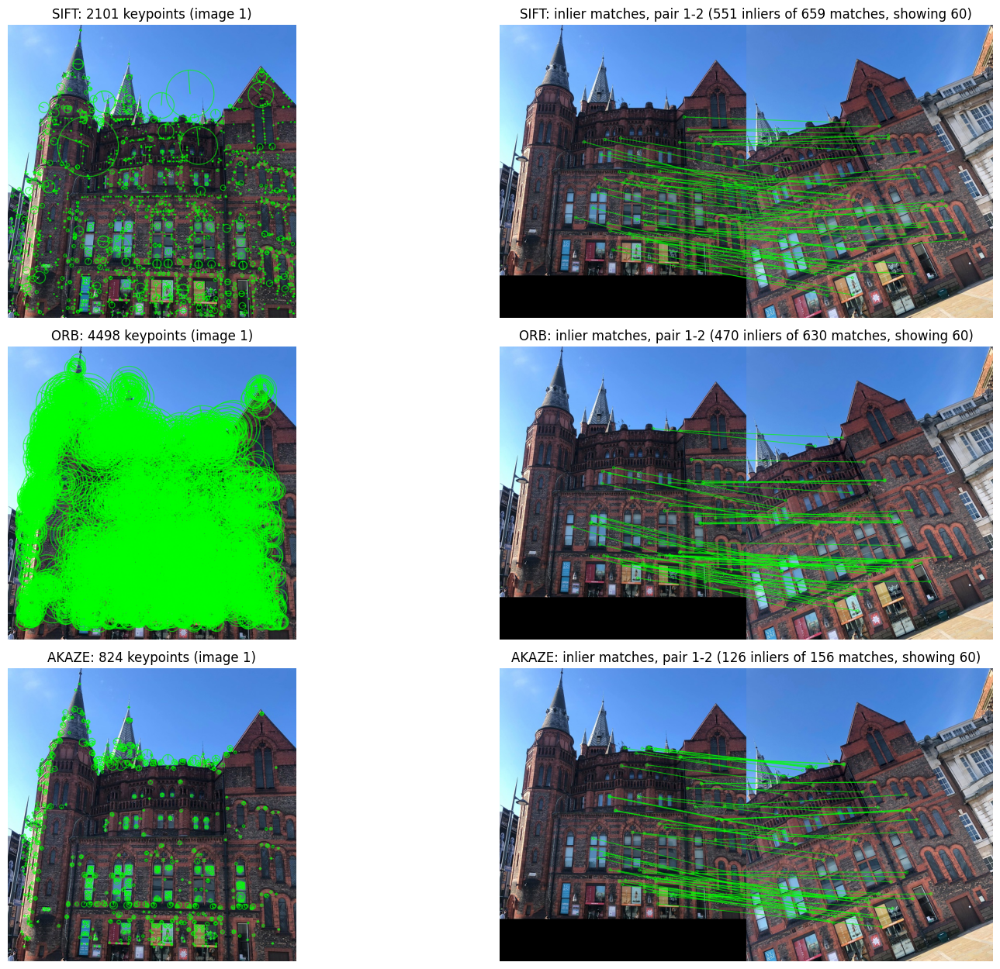

In [ ]:
# C3. Visual results: keypoints and inlier matches (pair 1-2), one row per detector
fig, axes = plt.subplots(len(DETECTORS), 2, figsize=(18, 4.2 * len(DETECTORS)))
axes = np.atleast_2d(axes)
for row, name in zip(axes, DETECTORS):
    (k1, d1), (k2, d2) = featsC[name][0], featsC[name][1]
    vis = cv2.drawKeypoints(imgsC[0], k1, None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    row[0].imshow(rgb(vis)); row[0].set_title(f"{name}: {len(k1)} keypoints (image 1)"); row[0].axis("off")
    good, _ = match_pair(name, d1, d2)
    r = est_homography(k1, k2, good, STITCH_THR)
    if r is None:
        row[1].set_title(f"{name}: not enough matches"); row[1].axis("off"); continue
    inl_matches = [m for m, f in zip(good, r[1]) if f]
    selm = np.random.default_rng(0).permutation(len(inl_matches))[:60]
    mv = cv2.drawMatches(imgsC[0], k1, imgsC[1], k2, [inl_matches[i] for i in selm], None,
                         matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    row[1].imshow(rgb(mv)); row[1].axis("off")
    row[1].set_title(f"{name}: inlier matches, pair 1-2 ({len(inl_matches)} inliers of {len(good)} matches, showing 60)")
fig.tight_layout(); savefig(fig, f"{OUT}/partC/C_keypoints_and_matches.png"); plt.show()

In [ ]:
# C4. Warping and blending
MAX_CANVAS = 6000

def build_chain(Hpair, ref):
    """Hpair[i]: image i -> image i+1. Returns H_i->ref."""
    n = len(Hpair) + 1
    Hs = [None] * n; Hs[ref] = np.eye(3)
    for i in range(ref - 1, -1, -1):
        Hs[i] = Hs[i + 1] @ Hpair[i]
    for i in range(ref + 1, n):
        Hs[i] = Hs[i - 1] @ np.linalg.inv(Hpair[i - 1])
    return [H / H[2, 2] for H in Hs]

def warp_all(imgs, Hs):
    corners = []
    for im, H in zip(imgs, Hs):
        h, w = im.shape[:2]
        c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        corners.append(cv2.perspectiveTransform(c, H).reshape(-1, 2))
    allc = np.vstack(corners)
    if not np.isfinite(allc).all():
        raise RuntimeError("Degenerate homography (infinite coordinates).")
    mn, mx = allc.min(0), allc.max(0)
    s = min(1.0, MAX_CANVAS / max(mx - mn))
    T = np.array([[s, 0, -mn[0] * s], [0, s, -mn[1] * s], [0, 0, 1]], dtype=np.float64)
    size = (int(math.ceil((mx[0] - mn[0]) * s)), int(math.ceil((mx[1] - mn[1]) * s)))
    warped, masks = [], []
    for im, H in zip(imgs, Hs):
        M = T @ H; h, w = im.shape[:2]
        warped.append(cv2.warpPerspective(im, M, size, flags=cv2.INTER_LINEAR))
        masks.append(cv2.warpPerspective(np.full((h, w), 255, np.uint8), M, size, flags=cv2.INTER_NEAREST))
    return warped, masks

def blend_feather(warped, masks):
    ws = [cv2.distanceTransform((m > 0).astype(np.uint8), cv2.DIST_L2, 3) for m in masks]
    num = sum(w[..., None] * im.astype(np.float32) for w, im in zip(ws, warped))
    den = sum(ws)[..., None]
    return np.clip(num / np.maximum(den, 1e-6), 0, 255).astype(np.uint8)

def _gauss_pyr(x, n):
    p = [x]
    for _ in range(n):
        p.append(cv2.pyrDown(p[-1]))
    return p

def _lap_pyr(x, n):
    g = _gauss_pyr(x, n)
    l = [g[i] - cv2.pyrUp(g[i + 1], dstsize=(g[i].shape[1], g[i].shape[0])) for i in range(n)]
    l.append(g[-1]); return l

def blend_multiband(warped, masks, levels=5):
    ws = np.stack([cv2.distanceTransform((m > 0).astype(np.uint8), cv2.DIST_L2, 3) for m in masks])
    win = np.argmax(ws, axis=0)
    covered = (np.stack(masks).max(0) > 0)
    hard = [((win == i) & covered).astype(np.float32) for i in range(len(warped))]
    lp = [_lap_pyr(im.astype(np.float32), levels) for im in warped]
    mp = [_gauss_pyr(h, levels) for h in hard]
    out_levels = []
    for l in range(levels + 1):
        num = sum(lp[i][l] * mp[i][l][..., None] for i in range(len(warped)))
        den = sum(mp[i][l] for i in range(len(warped)))[..., None]
        out_levels.append(num / np.maximum(den, 1e-6))
    res = out_levels[-1]
    for l in range(levels - 1, -1, -1):
        res = cv2.pyrUp(res, dstsize=(out_levels[l].shape[1], out_levels[l].shape[0])) + out_levels[l]
    res[~covered] = 0
    return np.clip(res, 0, 255).astype(np.uint8)

def run_full_pipeline(name, thr=STITCH_THR, blend="feather", ref=REF_IDX):
    """End-to-end: extract -> match -> RANSAC -> warp -> blend. Returns (panorama, info)."""
    t0 = time.perf_counter()
    feats, _ = extract(name, grays)
    Hpair, stats = [], []
    for i in range(N_IMG - 1):
        (k1, d1), (k2, d2) = feats[i], feats[i + 1]
        good, _ = match_pair(name, d1, d2)
        r = est_homography(k1, k2, good, thr)
        if r is None:
            raise RuntimeError(f"{name}: could not estimate H for pair {i+1}-{i+2} (matches={len(good)}).")
        Hpair.append(r[0]); stats.append(dict(good=len(good), inliers=int(r[1].sum()), rmse=r[2]))
    Hs = build_chain(Hpair, ref)
    warped, masks = warp_all(imgsC, Hs)
    pano = blend_feather(warped, masks) if blend == "feather" else blend_multiband(warped, masks)
    total_ms = (time.perf_counter() - t0) * 1000
    info = dict(Detector=name, Blend=blend,
                Keypoints_total=sum(len(f[0]) for f in feats),
                Initial_matches=sum(s["good"] for s in stats), Inliers=sum(s["inliers"] for s in stats),
                Mean_Reproj_RMSE_px=float(np.mean([s["rmse"] for s in stats])), Total_stitch_time_ms=total_ms)
    info["Inlier_ratio_pct"] = 100 * info["Inliers"] / max(info["Initial_matches"], 1)
    return pano, info

panos, rows_sum = {}, []
for name in DETECTORS:
    try:
        pano, info = run_full_pipeline(name, STITCH_THR, "feather")
        panos[name] = pano; rows_sum.append(info)
        cv2.imwrite(f"{OUT}/partC/panorama_{name}.jpg", pano)
    except Exception as e:
        print("FAILED:", name, "->", e)

# bonus: multi-band blending with the first detector
BONUS = DETECTORS[0]
pano_mb = None
try:
    pano_mb, info = run_full_pipeline(BONUS, STITCH_THR, "multiband")
    rows_sum.append(info)
    cv2.imwrite(f"{OUT}/partC/panorama_{BONUS}_multiband.jpg", pano_mb)
except Exception as e:
    print("Multi-band bonus failed:", e)

dfC_final = pd.DataFrame(rows_sum)[["Detector", "Blend", "Keypoints_total", "Initial_matches", "Inliers",
                                    "Inlier_ratio_pct", "Mean_Reproj_RMSE_px", "Total_stitch_time_ms"]].round(3)
display(dfC_final); dfC_final.to_csv(f"{OUT}/tables/partC_detector_comparison.csv", index=False)

,Detector,Blend,Keypoints_total,Initial_matches,Inliers,Inlier_ratio_pct,Mean_Reproj_RMSE_px,Total_stitch_time_ms
0,SIFT,feather,11004,2062,1766,85.645,0.966,1813.191
1,ORB,feather,19306,2255,1686,74.767,1.392,1506.471
2,AKAZE,feather,6065,1261,1056,83.743,0.977,814.912
3,SIFT,multiband,11004,2062,1766,85.645,0.966,2008.655


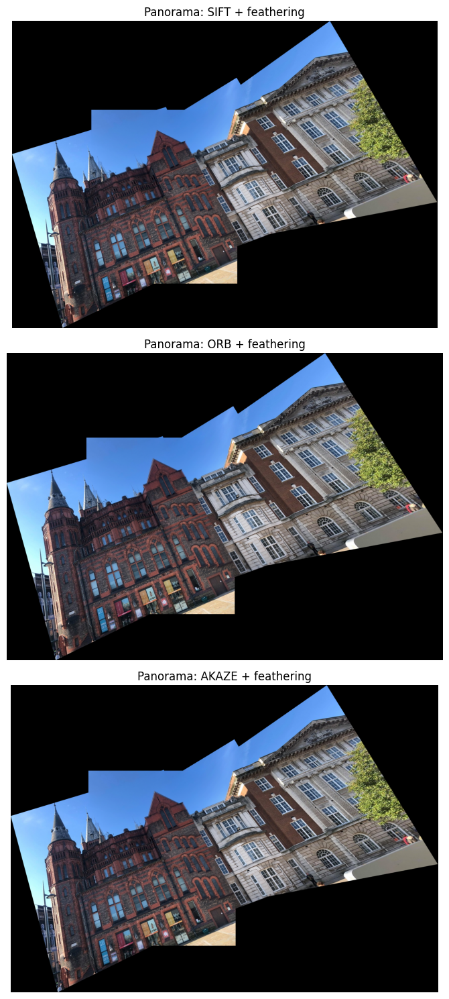

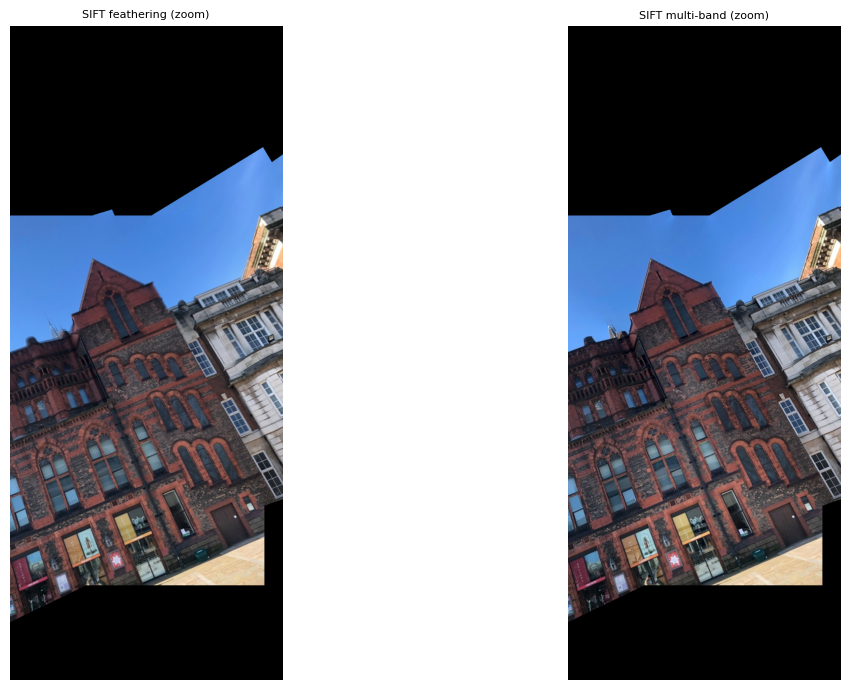

In [ ]:
# C5. Final panoramas (one per detector) and the multi-band bonus
fig, axes = plt.subplots(len(panos), 1, figsize=(16, 5 * len(panos)))
axes = np.atleast_1d(axes)
for ax, (name, pano) in zip(axes, panos.items()):
    ax.imshow(rgb(pano)); ax.axis("off"); ax.set_title(f"Panorama: {name} + feathering")
fig.tight_layout(); savefig(fig, f"{OUT}/partC/C_panoramas.png"); plt.show()

if pano_mb is not None and BONUS in panos:
    a, b = panos[BONUS], pano_mb
    x0, x1 = int(a.shape[1] * 0.25), int(a.shape[1] * 0.55)
    show_grid([a[:, x0:x1], b[:, x0:x1]], [f"{BONUS} feathering (zoom)", f"{BONUS} multi-band (zoom)"], 2,
              f"{OUT}/partC/C_blending_bonus.png", cell=7)

# COMPARATIVE ANALYSIS (15 pts) - summary chart

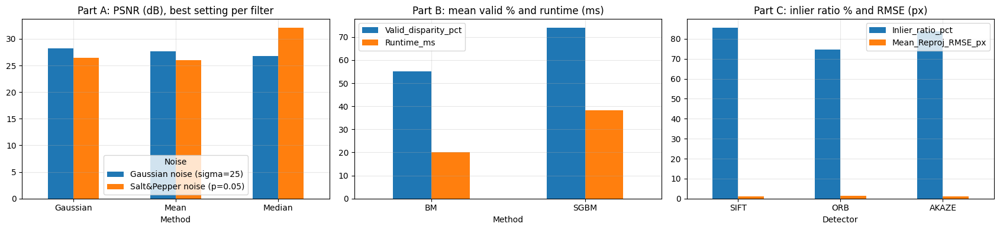

In [ ]:
best_tbl = (dfA[dfA.Noise.isin(noisy) & dfA.Method.isin(["Mean", "Gaussian", "Median"])]
            .loc[lambda d: d.groupby(["Noise", "Method"]).PSNR_dB.idxmax()])
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
best_tbl.pivot(index="Method", columns="Noise", values="PSNR_dB").plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Part A: PSNR (dB), best setting per filter"); axes[0].grid(alpha=.3)
cols = ["Valid_disparity_pct", "Runtime_ms"]
dfB.groupby("Method")[cols].mean().plot.bar(ax=axes[1], rot=0)
axes[1].set_title("Part B: mean valid % and runtime (ms)"); axes[1].grid(alpha=.3)
dfC_final[dfC_final.Blend == "feather"].set_index("Detector")[["Inlier_ratio_pct", "Mean_Reproj_RMSE_px"]].plot.bar(ax=axes[2], rot=0)
axes[2].set_title("Part C: inlier ratio % and RMSE (px)"); axes[2].grid(alpha=.3)
fig.tight_layout(); savefig(fig, f"{OUT}/summary_charts.png"); plt.show()

In [ ]:
# Package the results for submission
shutil.make_archive("results_outputs", "zip", OUT)
print("Created results_outputs.zip")
try:
    from google.colab import files
    files.download("results_outputs.zip")
except Exception:
    pass

Created results_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>